# MSDS 400 Fundamental Theorem of Calculus

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Sample function

def f(x):
    f = 1997 + 15*x**30  # Students can supply a function at this point.
    return f

`integrate()` is a general numerical integration function. It requires an interval [a,b] and n = the number of subintervals used for integration. The code below uses the function, f, as defined f above.  

In [2]:
def integrate(a, b, n):
    total = 0.0
    delta = (b - a) / n
    for i in range(n):
        total = total + delta * (f(a + delta * (i + 1)) + f(a + delta * i)) / 2
    return total

# This defines the parameters for integration.

c = 4.0
b = 24.0
a = 0.0
n = 100000  # 15x^30 is very steep near x = 24, so the trapezoid rule needs a fine grid

This f(x) is positive on all of [0, 24], so there is no negative area to separate out and the total is the single integral from a to b. The exact value from the Fundamental Theorem, F(24) - F(0) with F(x) = 1997x + 15x<sup>31</sup>/31, is printed for comparison.

Revision note (2026): the earlier version also added the integral from b = 24 back to c = 4, which counted the area over [4, 24] a second time and roughly doubled the answer (5.96e42 instead of about 2.96e42).

In [3]:
area = integrate(a, b, n)

print("Final Estimate of Total Profits = {}".format(area))

def F(x):
    return 1997*x + 15*x**31/31  # Antiderivative of f

print("Exact value F(b) - F(a) = {}".format(F(b) - F(a)))

Final Estimate of Total Profits = 2.959906971821666e+42
Exact value F(b) - F(a) = 2.959906948882388e+42


The next section of code shows how to plot different colors by dividing the interval based on which area is negative.

`fill_between()` requires an array for x and two functions for y between which the color is filled. In this case we use 0.0 for the x-axis and y. `alpha` controls the intensity of the color.

This section sets up the dimensions of the plot and creates it. We have to consider both plots and find the min and max of y for plot limits.

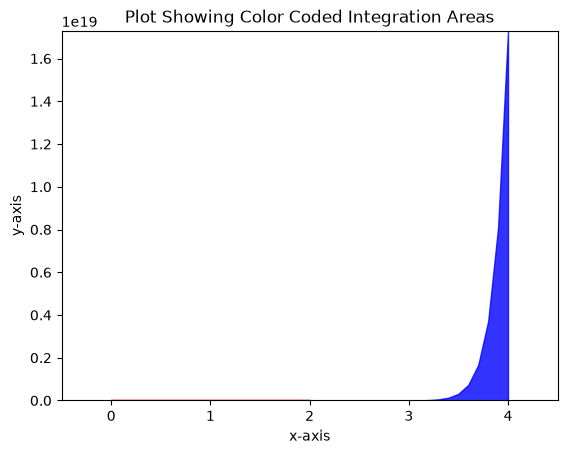

In [4]:
x = np.arange(0.0, 2.1, 0.1)  # This defines the interval for the color red.
y = f(x)

x1 = np.arange(2.0, 4.1, 0.1)  # This defines the interval for the color blue.
y1 = f(x1)

plt.figure()
plt.fill_between(x, 0, y, color='r', alpha=0.8)
plt.fill_between(x1, 0.0, y1, color='b', alpha=0.8)

ymin = min(min(y), min(y1))
ymax = max(max(y), max(y1))
plt.xlim(-0.5, 4.5)
plt.ylim(ymin - 1.0, ymax + 1.0)

plt.xlabel('x-axis')
plt.ylabel('y-axis')
plt.title('Plot Showing Color Coded Integration Areas')
plt.show()

This section of code shows how to plot different colors using a
logical operator in the plotting statement.  The operator will
control when each color is used.

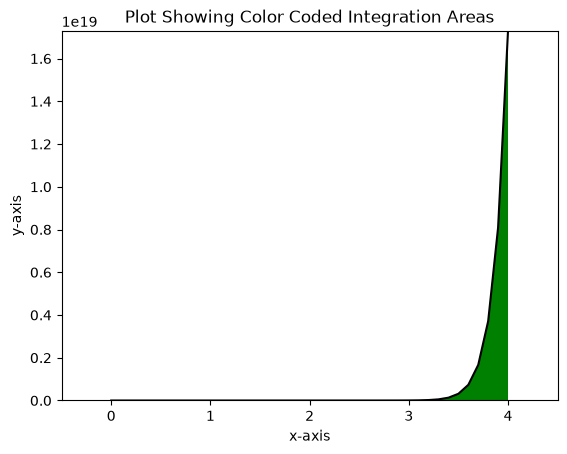

In [5]:
plt.figure()  # This separates the two plots from each other.
x = np.arange(0.0, 4.1, 0.1)  # This defines the interval for color filling.
y = f(x)
plt.plot(x, y, c='k')

# This shows how to fill between the lines using an inequality.

plt.fill_between(x, 0.0, y, where=y < 0.0, facecolor='y', interpolate=True)
plt.fill_between(x, 0.0, y, where=y > 0.0, facecolor='g', interpolate=True)

plt.xlim(-0.5, 4.5)
plt.ylim(ymin - 1.0, ymax + 1.0)
plt.xlabel('x-axis')
plt.ylabel('y-axis')
plt.title('Plot Showing Color Coded Integration Areas')
plt.show()